# Figure 1e. Structured global simulation

The global benchmark tests recovery of variant-gene *trans* effects in a directed network. Forty active variants form eight five-variant blocks, each connected to a proximal *cis* mediator; effects propagate through nine distal genes. Twenty additional variants have no *trans* effect. The resulting 60-by-9 ground-truth matrix contains 160 positive variant-gene pairs. This panel specifies the simulated architecture, not method performance.

Input: `data/Figure_1e_global_simulation_network.rds` (plot-ready network nodes, edges and pair-level truth).

Warning message:
"package 'ggplot2' was built under R version 4.4.3"


Warning message:
"The `label.size` argument of `geom_label()` is deprecated as of ggplot2 3.5.0.
i Please use the `linewidth` argument instead."


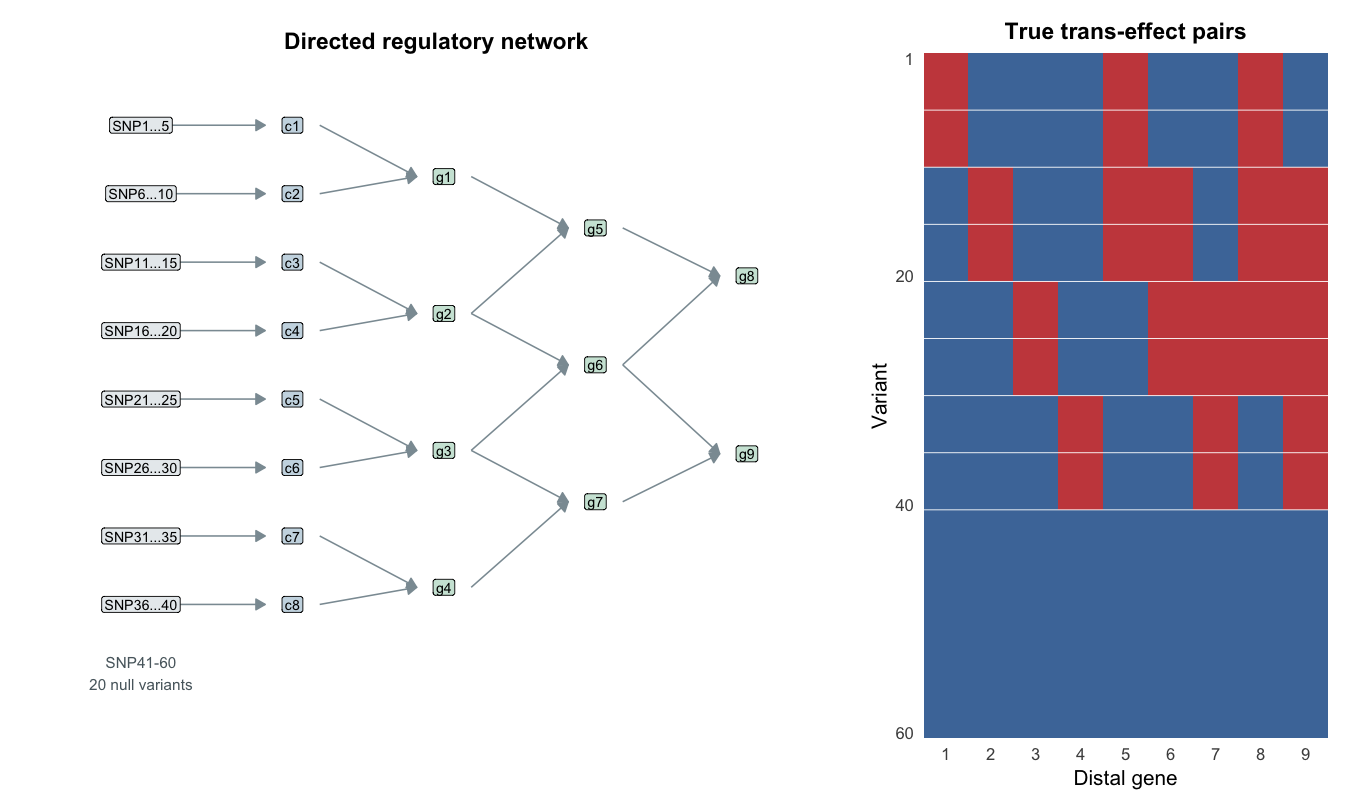

In [1]:
suppressPackageStartupMessages(library(ggplot2))
suppressPackageStartupMessages(library(patchwork))
x <- readRDS("data/Figure_1e_global_simulation_network.rds")
stopifnot(nrow(x$nodes) == 25L, nrow(x$edges) == 26L,
          nrow(x$truth) == 540L, sum(x$truth$truth) == 160L)
nodes <- x$nodes
edges <- x$edges
truth <- x$truth
nodes$kind <- factor(nodes$kind,
                     levels = c("SNP block", "cis mediator", "distal gene"))
network <- ggplot() +
  geom_segment(data = edges,
               aes(x = x + 0.18, y = y, xend = xend - 0.18, yend = yend),
               linewidth = 0.35, color = "#8B9BA2",
               arrow = grid::arrow(length = grid::unit(1.8, "mm"),
                                   type = "closed")) +
  geom_label(data = nodes, aes(x, y, label = label, fill = kind),
             label.size = 0.2, size = 2.4,
             label.padding = grid::unit(0.17, "lines")) +
  annotate("text", x = 0, y = 0, label = "SNP41-60\n20 null variants",
           size = 2.6, color = "#59676D") +
  scale_fill_manual(values = c("SNP block" = "#E8ECEE",
                               "cis mediator" = "#CADAE4",
                               "distal gene" = "#CDE5D9"), guide = "none") +
  coord_cartesian(xlim = c(-0.6, 4.5), ylim = c(-0.5, 8.6), clip = "off") +
  labs(title = "Directed regulatory network") +
  theme_void(base_size = 10) +
  theme(plot.title = element_text(face = "bold", size = 11, hjust = 0.5))
truth_plot <- ggplot(truth, aes(x = gene, y = snp, fill = factor(truth))) +
  geom_tile() +
  geom_hline(yintercept = seq(5.5, 40.5, by = 5),
             linewidth = 0.2, color = "white") +
  scale_fill_manual(values = c("0" = "#4B78A8",
                               "1" = "#C94B4B"), guide = "none") +
  scale_x_continuous(breaks = 1:9, expand = c(0, 0)) +
  scale_y_reverse(breaks = c(1, 20, 40, 60), expand = c(0, 0)) +
  labs(x = "Distal gene", y = "Variant", title = "True trans-effect pairs") +
  theme_minimal(base_size = 10) +
  theme(panel.grid = element_blank(),
        plot.title = element_text(face = "bold", size = 11, hjust = 0.5))
options(repr.plot.width = 9, repr.plot.height = 5.4, repr.plot.res = 150)
print(network + truth_plot + plot_layout(widths = c(2.1, 1)))